# Mall Corridor Monitoring with YOLO26n
CSIT3110 / DSCI5420 · Assignment 10: Object Detection Using YOLO

This notebook counts people in a self-chosen polygon zone of a shopping-mall corridor video, once per second, and plots how the counts change.

In [1]:
import os, math
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ultralytics import YOLO

VIDEO_PATH = "mall_corridor.mpg"   # saved beside this notebook
MODEL_PATH = "yolo26n.pt"          # pretrained YOLO26n (auto-downloads if missing)
PERSON_CLASS = 0                   # COCO class id for "person"

def to_rgb(img):
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

def show(img, title="", figsize=(8, 6)):
    plt.figure(figsize=figsize); plt.imshow(to_rgb(img)); plt.title(title); plt.axis("off"); plt.show()
print("OpenCV", cv2.__version__)

OpenCV 5.0.0


## Section 1: Load and inspect the video

In [2]:
cap = cv2.VideoCapture(VIDEO_PATH)
assert cap.isOpened(), f"Could not open {VIDEO_PATH}"
width  = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
fps    = cap.get(cv2.CAP_PROP_FPS)

# The .mpg container's frame-count metadata is unreliable, so read every frame once
# and keep them in memory (small 384x288 frames, so this is cheap).
frames = []
while True:
    ok, f = cap.read()
    if not ok:
        break
    frames.append(f)
cap.release()
n_frames = len(frames)
duration = n_frames / fps

print(f"Frame width : {width} px")
print(f"Frame height: {height} px")
print(f"Frame rate  : {fps:.2f} fps")
print(f"Total frames: {n_frames}  (duration about {duration:.1f} s)")

Frame width : 384 px
Frame height: 288 px
Frame rate  : 25.00 fps
Total frames: 2360  (duration about 94.4 s)


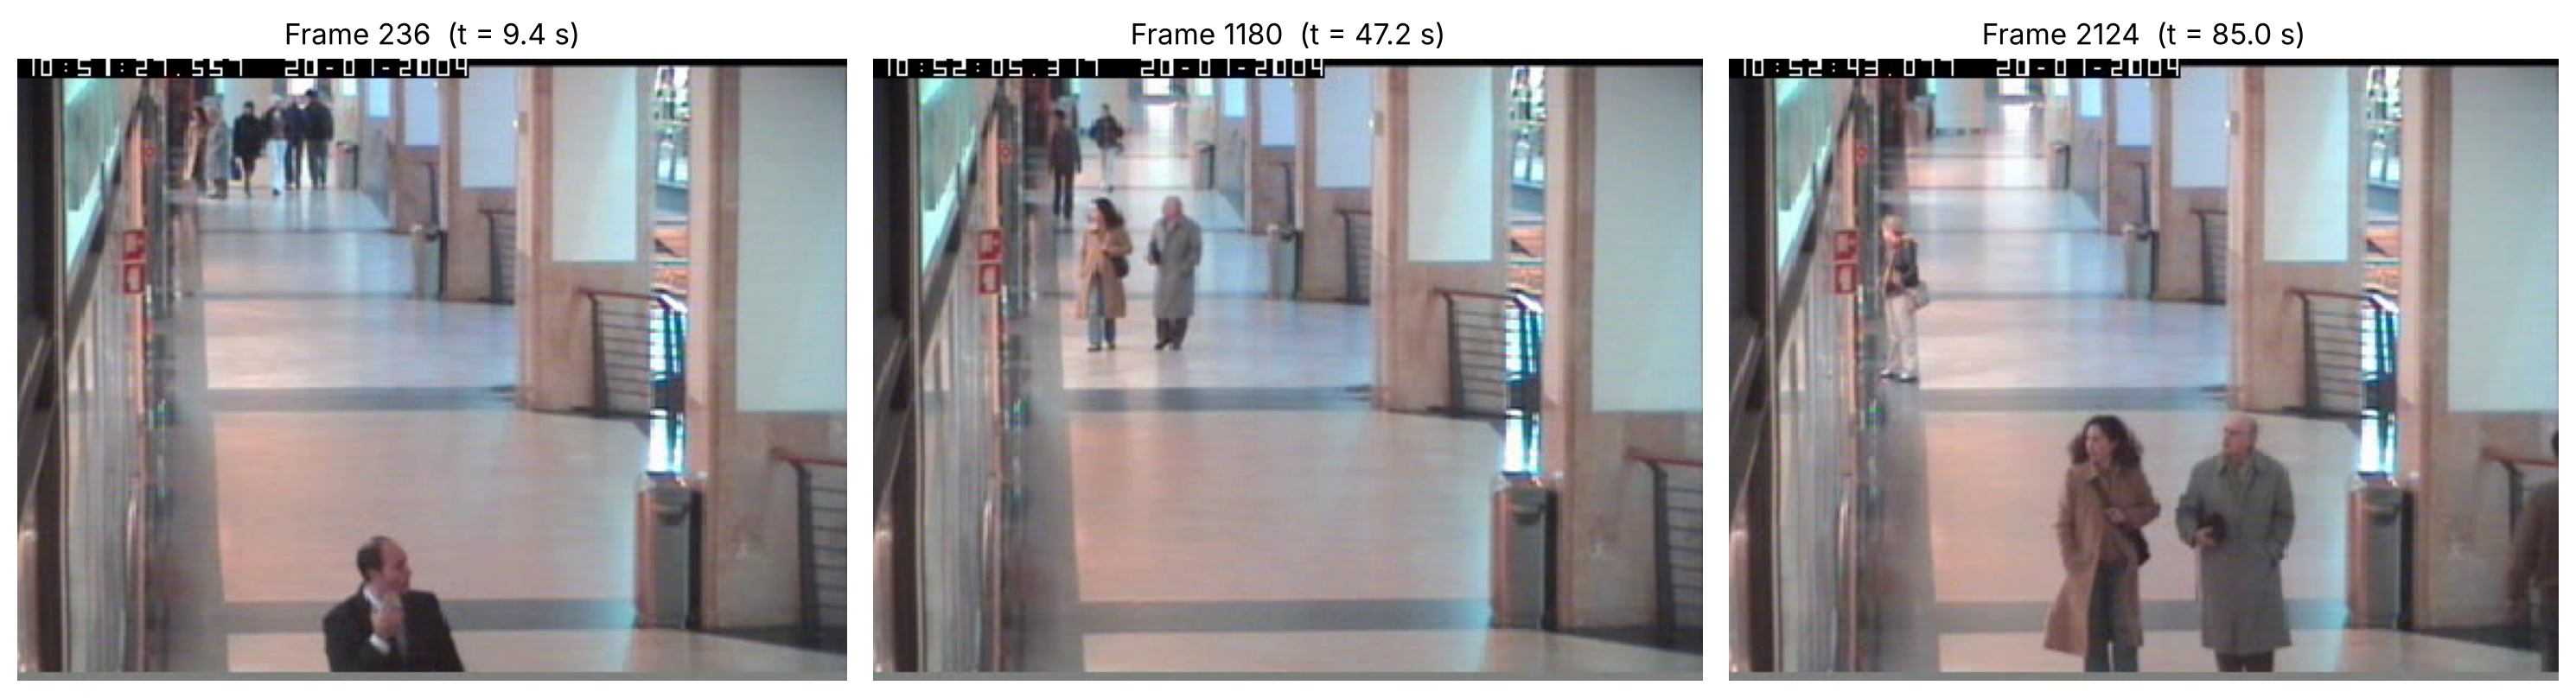

In [3]:
idxs = [int(n_frames * p) for p in (0.10, 0.50, 0.90)]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, i in zip(axes, idxs):
    ax.imshow(to_rgb(frames[i])); ax.set_title(f"Frame {i}  (t = {i/fps:.1f} s)"); ax.axis("off")
plt.tight_layout(); plt.show()

## Section 2: Define my own zone

Zone corner coordinates (x, y):
  P1: (75, 285)
  P2: (105, 130)
  P3: (225, 130)
  P4: (305, 285)


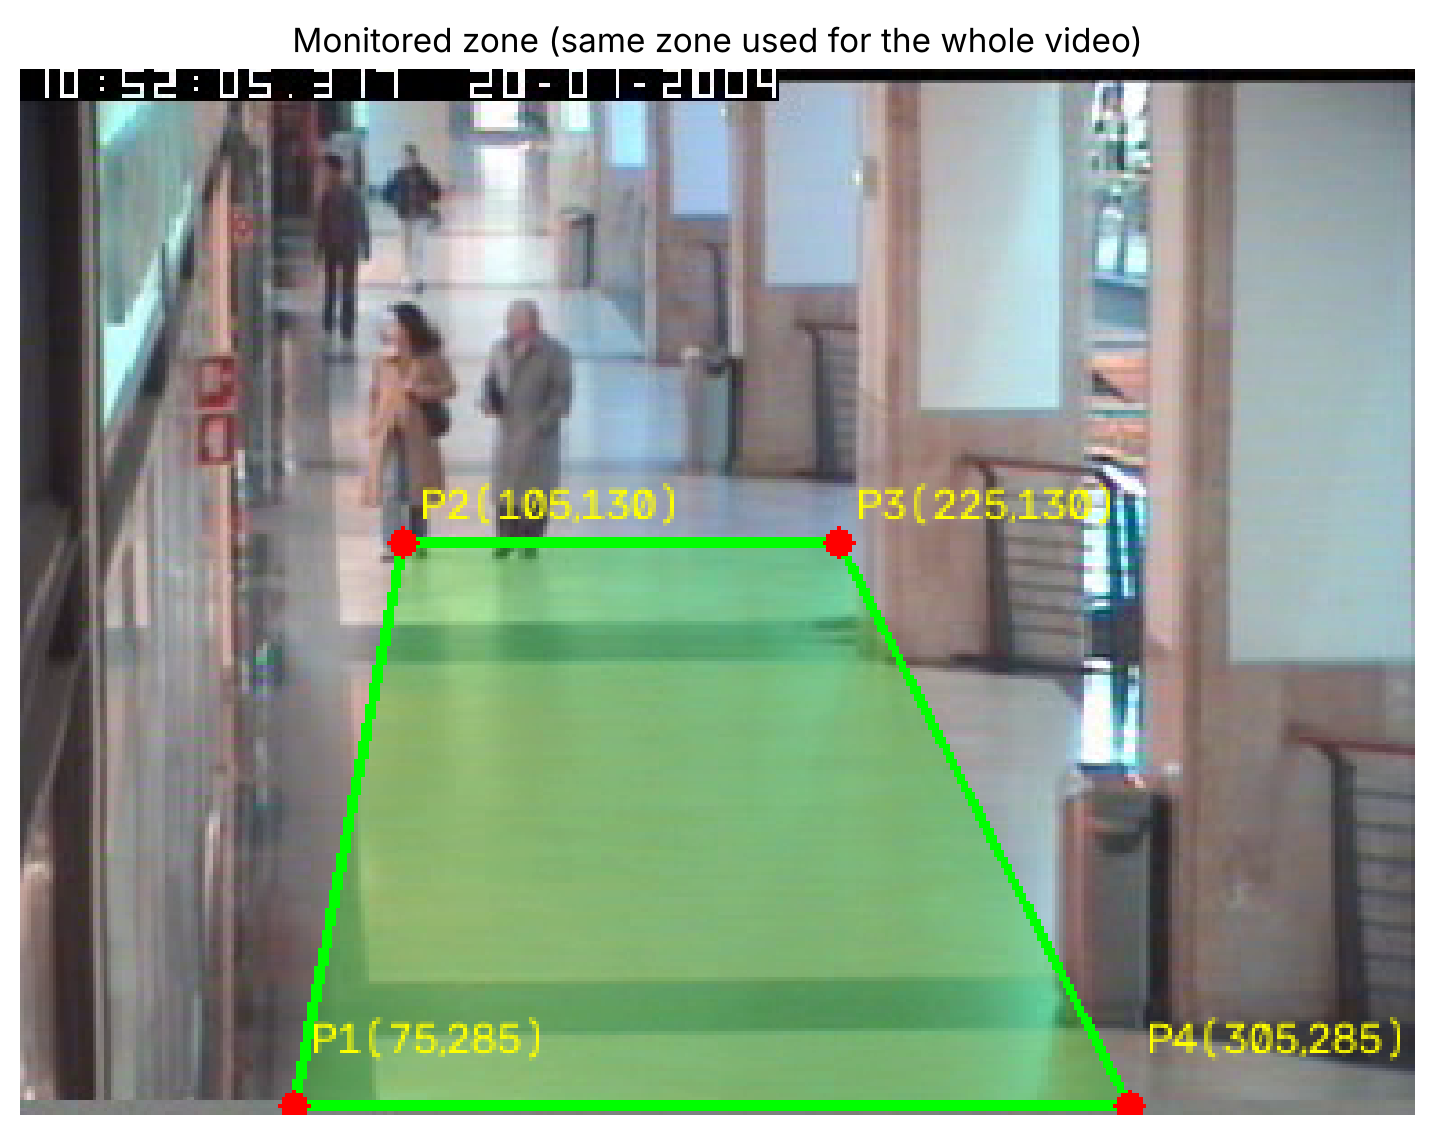

In [4]:
# Zone corners as (x, y) pixels, listed in order around the polygon.
ZONE = np.array([
    [75, 285],    # bottom-left
    [105, 130],   # top-left
    [225, 130],   # top-right
    [305, 285],   # bottom-right
], dtype=np.int32)

def draw_zone(img, color=(0, 255, 0), alpha=0.25):
    out = img.copy()
    overlay = out.copy()
    cv2.fillPoly(overlay, [ZONE], color)
    out = cv2.addWeighted(overlay, alpha, out, 1 - alpha, 0)
    cv2.polylines(out, [ZONE], True, color, 2)
    for k, (x, y) in enumerate(ZONE):
        cv2.circle(out, (int(x), int(y)), 4, (0, 0, 255), -1)
        cv2.putText(out, f"P{k+1}({x},{y})", (int(x)+5, int(y)-6 if k in (1,2) else int(y)-14),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.4, (0, 255, 255), 1, cv2.LINE_AA)
    return out

print("Zone corner coordinates (x, y):")
for k, (x, y) in enumerate(ZONE, 1):
    print(f"  P{k}: ({x}, {y})")
show(draw_zone(frames[n_frames // 2]), "Monitored zone (same zone used for the whole video)", (9, 7))

**Why this zone:** The zone is a trapezoid covering the corridor floor in front of the camera, from the base of the frame up to roughly the middle of the walkway. It follows the perspective of the corridor, so its sides run along the shop-front wall on the left and the pillar and bin on the right. I chose it because it is the main walking lane that every shopper passing the shop fronts must cross, so it shows real foot traffic rather than people standing far away. It is also close enough to the camera that people are large and detected reliably.


## Section 3: Detect and count people

In [5]:
model = YOLO(MODEL_PATH)

def detect_people(img, conf):
    """Run YOLO26n and keep only person detections. Returns array of [x1,y1,x2,y2,conf]."""
    res = model.predict(img, conf=conf, classes=[PERSON_CLASS], imgsz=640, verbose=False)[0]
    if len(res.boxes) == 0:
        return np.zeros((0, 5))
    return np.hstack([res.boxes.xyxy.cpu().numpy(), res.boxes.conf.cpu().numpy()[:, None]])

def bottom_centre(box):
    x1, y1, x2, y2 = box[:4]
    return ((x1 + x2) / 2.0, y2)

def in_zone(box):
    # >= 0 means inside OR exactly on the boundary
    return cv2.pointPolygonTest(ZONE.astype(np.float32), bottom_centre(box), False) >= 0

def annotate(img, dets, draw_zone_too=True):
    out = draw_zone(img) if draw_zone_too else img.copy()
    for d in dets:
        inside = in_zone(d)
        col = (0, 200, 0) if inside else (0, 0, 255)
        x1, y1, x2, y2 = map(int, d[:4])
        cv2.rectangle(out, (x1, y1), (x2, y2), col, 2)
        bx, by = map(int, bottom_centre(d))
        cv2.circle(out, (bx, by), 4, (255, 0, 255), -1)
        cv2.putText(out, f"{d[4]:.2f}", (x1, max(y1-4, 10)), cv2.FONT_HERSHEY_SIMPLEX, 0.4, col, 1, cv2.LINE_AA)
    return out

### 3.2 Compare confidence thresholds 0.10, 0.25, 0.60 on the same frame

conf 0.10: 7 detections, confidences = [0.8500000238418579, 0.6600000262260437, 0.6499999761581421, 0.5699999928474426, 0.27000001072883606, 0.14000000059604645, 0.11999999731779099]
conf 0.25: 5 detections, confidences = [0.8500000238418579, 0.6600000262260437, 0.6499999761581421, 0.5699999928474426, 0.27000001072883606]
conf 0.60: 3 detections, confidences = [0.8500000238418579, 0.6600000262260437, 0.6499999761581421]


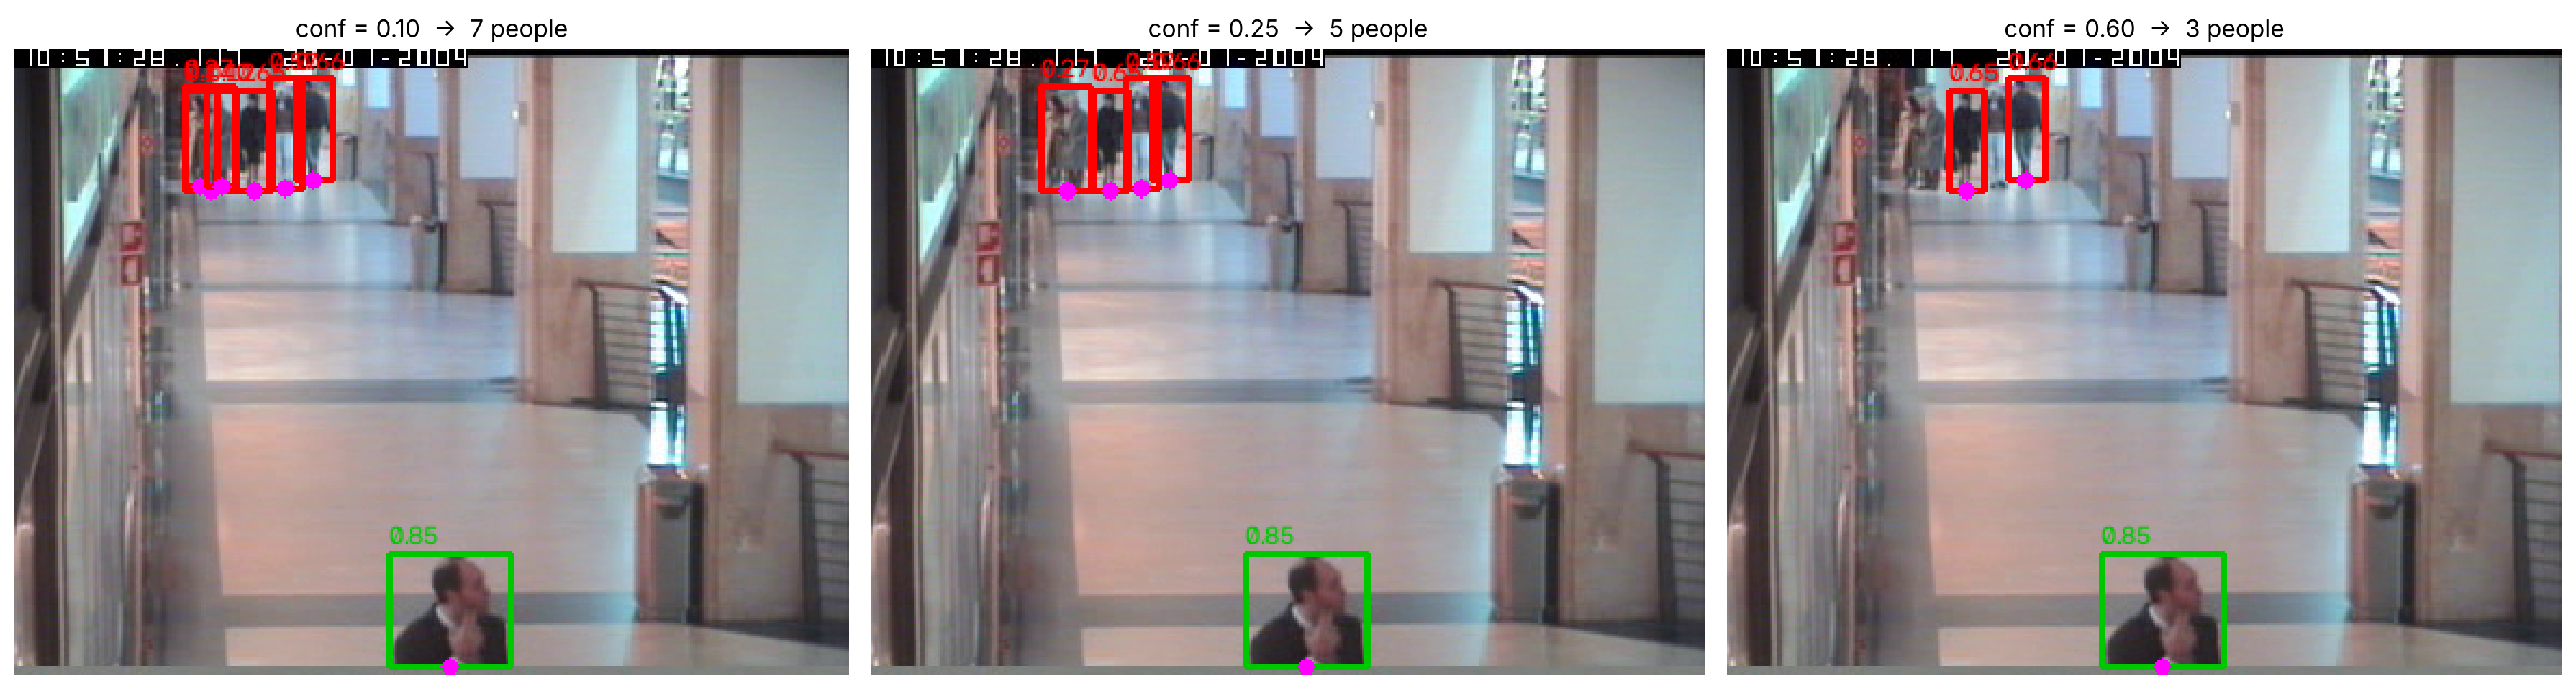

In [6]:
FRAME_IDX = int(os.environ.get("CMP_FRAME", "250"))   # a frame with several people at different distances
cmp_frame = frames[FRAME_IDX]
THRESHOLDS = [0.10, 0.25, 0.60]
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, th in zip(axes, THRESHOLDS):
    dets = detect_people(cmp_frame, th)
    ax.imshow(to_rgb(annotate(cmp_frame, dets, draw_zone_too=False)))
    ax.set_title(f"conf = {th:.2f}  ->  {len(dets)} people"); ax.axis("off")
    print(f"conf {th:.2f}: {len(dets)} detections, confidences = {np.round(np.sort(dets[:,4])[::-1],2).tolist()}")
plt.tight_layout(); plt.show()

**Choice: 0.25.** At 0.10 the detector adds low-confidence boxes (0.14 and 0.12 here) that overlap the real people in the far group, so counts are inflated by duplicates and false positives. At 0.60 it drops genuine people that it is less sure about (the 0.57 and 0.27 detections here), so the count is too low, especially for small, distant people. 0.25 keeps the clear detections and still catches the partly visible people without the extra duplicate boxes.

In [7]:
CONF = 0.25   # chosen threshold for all remaining work

### 3.3 and 3.4 Zone membership and one annotated frame

A person counts as inside the zone when the **bottom-centre point** of their bounding box, `((x1+x2)/2, y2)`, satisfies `cv2.pointPolygonTest(...) >= 0` (inside or on the boundary). Green boxes are inside the zone, red boxes are outside, and the magenta dot is the bottom-centre point.

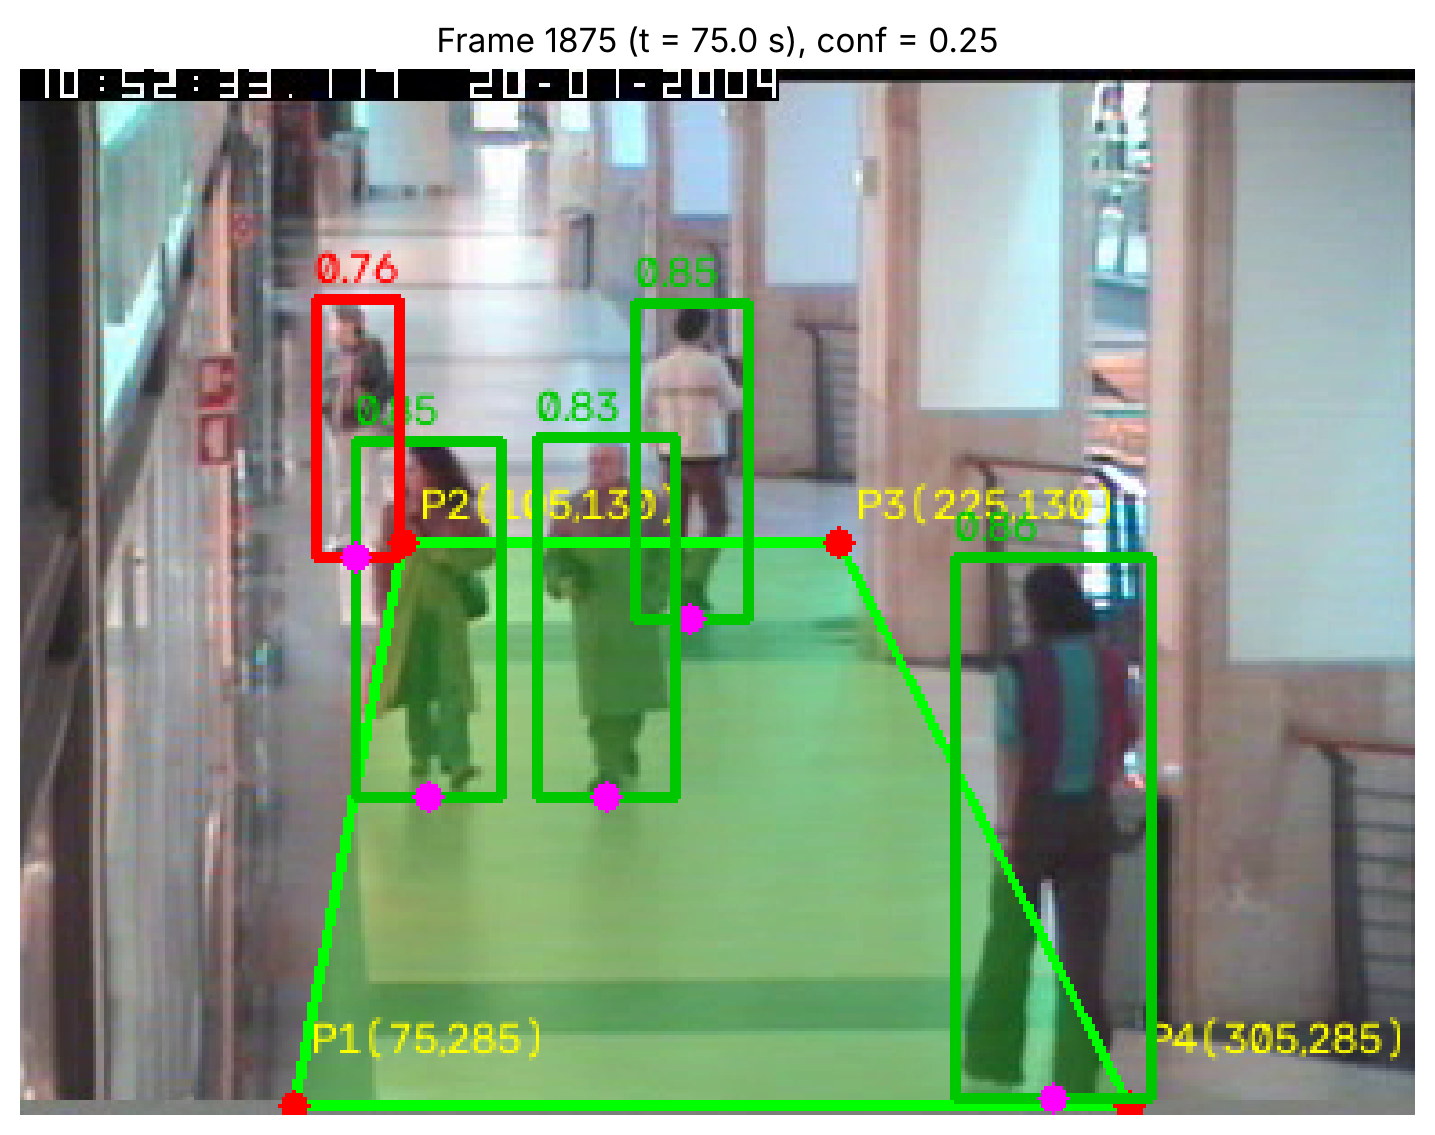

Total people detected in frame : 5
People inside the zone         : 4


In [8]:
SHOW_IDX = int(os.environ.get("SHOW_FRAME", "1875"))
dets = detect_people(frames[SHOW_IDX], CONF)
total = len(dets)
inside = int(sum(in_zone(d) for d in dets))
show(annotate(frames[SHOW_IDX], dets), f"Frame {SHOW_IDX} (t = {SHOW_IDX/fps:.1f} s), conf = {CONF}", (9, 7))
print(f"Total people detected in frame : {total}")
print(f"People inside the zone         : {inside}")

## Section 4: Record and plot the counts

In [9]:
records = []
t = 0
while True:
    idx = int(round(t * fps))          # one frame every one second
    if idx >= n_frames:
        break
    dets = detect_people(frames[idx], CONF)
    records.append({
        "time_s": t,
        "in_view": len(dets),
        "in_zone": int(sum(in_zone(d) for d in dets)),
    })
    t += 1

df = pd.DataFrame(records, columns=["time_s", "in_view", "in_zone"])
df.to_csv("mall_records.csv", index=False)
print(f"Saved {len(df)} records to mall_records.csv")
df.head(10)

Saved 95 records to mall_records.csv


,time_s,in_view,in_zone
0,0,4,0
1,1,4,0
2,2,4,0
3,3,3,0
4,4,6,0
5,5,4,0
6,6,5,0
7,7,5,0
8,8,6,1
9,9,6,1


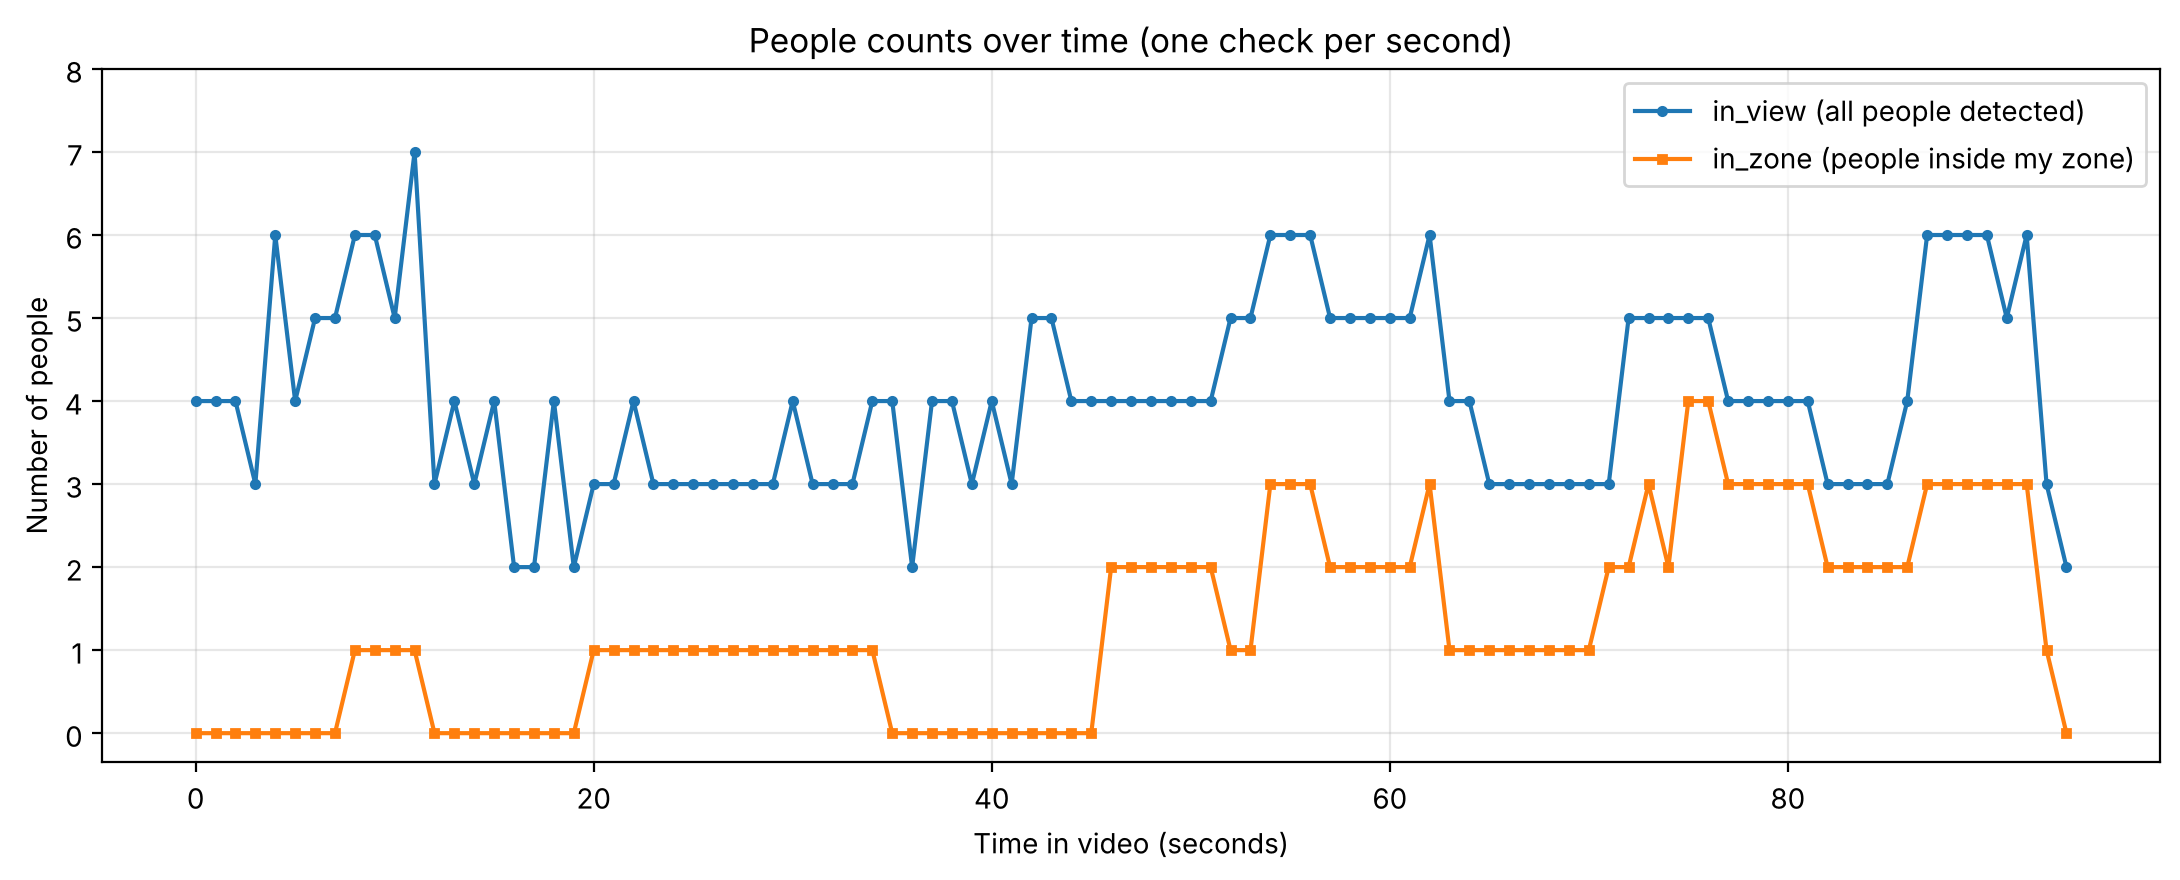

In [10]:
plt.figure(figsize=(11, 4.5))
plt.plot(df["time_s"], df["in_view"], marker="o", ms=3, label="in_view (all people detected)")
plt.plot(df["time_s"], df["in_zone"], marker="s", ms=3, label="in_zone (people inside my zone)")
plt.xlabel("Time in video (seconds)"); plt.ylabel("Number of people")
plt.title("People counts over time (one check per second)")
plt.yticks(range(0, int(df["in_view"].max()) + 2))
plt.grid(alpha=0.3); plt.legend(); plt.tight_layout(); plt.show()

In [11]:
max_zone = int(df["in_zone"].max())
peak_times = df.loc[df["in_zone"] == max_zone, "time_s"].tolist()
print(f"Highest zone count: {max_zone}")
print(f"Occurred at time(s) (s): {peak_times}")
print(f"Mean in_zone = {df['in_zone'].mean():.2f}; seconds with at least one person in zone = {(df['in_zone']>0).sum()} of {len(df)}")
print(f"Mean in_view = {df['in_view'].mean():.2f}; max in_view = {int(df['in_view'].max())}")

Highest zone count: 4
Occurred at time(s) (s): [75, 76]
Mean in_zone = 1.31; seconds with at least one person in zone = 67 of 95
Mean in_view = 4.06; max in_view = 7


## Section 5: Questions and conclusion

**Q1. Why use the bottom-centre point to decide whether a person is inside the zone?**
The bottom-centre of a bounding box is where the person's feet touch the floor, and the zone is a region drawn on the floor. The box centre or top corners sit well above the floor in the image, so a tall person standing outside the zone could look inside it just because their head overlaps the polygon in the camera view. The feet point gives the person's actual ground position and is consistent for people of different heights and distances.

**Q2. Why does adding the counts across all checks fail to give the number of unique shoppers?**
The same person is counted again at every one-second check while they remain in the zone, so someone who spends 5 seconds in the zone adds 5 to the total. The detector also has no identity memory, so it cannot tell that the person in one check is the same person as in the next. Counting unique shoppers would need tracking, such as assigning IDs across frames, instead of per-frame counts.


### Conclusion
The chosen zone covers the walking lane in front of the camera. Over the 94 seconds (95 one-second checks), the zone was occupied in 67 checks and empty in 28. The zone count averaged 1.31 people (the whole view averaged 4.06), and the highest count was 4, at t = 75 s and 76 s. The zone was quiet for the first 45 seconds (average about 0.3 to 0.7 people per check) and then became busier, reaching its highest average of about 2.8 people per check in the 75 to 90 second window, with counts of 3 or more at several points between 54 s and 92 s. A manager could use this to see when this part of the corridor is busiest and plan staffing, cleaning or promotional displays around those periods, and could compare the same zone across days or hours. Because the counts are per-second snapshots and repeat people who linger, they measure how crowded the area is, not how many different shoppers visited, and the result comes from a single short clip, so it should be confirmed on longer footage before decisions are made.
